# Food Calorie Prediction from Images

This notebook implements a Convolutional Neural Network (CNN) model to predict the calorie content of food items from images. We'll use the NutritionVerse-Real dataset, which contains 889 images of 251 distinct dishes across 45 unique food types.

## Project Structure
1. Dataset Download & Exploration
2. Data Preprocessing & Augmentation 
3. CNN Model Architecture Design
4. Model Training & Evaluation
5. Gradio Interface Integration

Let's begin!

## 1. Environment Setup & Dataset Download

First, let's install the necessary packages and download the dataset from Kaggle.

In [ ]:
# Install required packages
!pip install tensorflow numpy pandas matplotlib seaborn scikit-learn kaggle gradio pillow opencv-python

# Set up Kaggle API credentials (you need to upload your kaggle.json file)
import os
import json

# Uncomment the following if you're in Google Colab
# uploaded = files.upload()  # Upload kaggle.json
# os.makedirs('/root/.kaggle', exist_ok=True)
# with open('/root/.kaggle/kaggle.json', 'w') as f:
#     f.write(json.dumps(json.loads(next(iter(uploaded.values())).decode())))
# os.chmod('/root/.kaggle/kaggle.json', 600)

# For local environment, ensure your kaggle.json is in ~/.kaggle/ with proper permissions

In [ ]:
# Download the NutritionVerse-Real dataset
# !kaggle datasets download -d nutritionverse/nutritionverse-real --force
# !unzip -q nutritionverse-real.zip -d nutritionverse-data

## 2. Data Exploration & Understanding

Let's explore the dataset structure and examine some sample images and metadata.

In [17]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import json

# Setting paths
base_path = 'nutritionverse-data'
images_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images')
coco_json_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images/_annotations.coco.json')
splits_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/updated-manual-dataset-splits.csv')

# Load COCO format image metadata
with open(coco_json_path, 'r') as f:
    coco_data = json.load(f)

print(f"COCO metadata loaded with {len(coco_data['images'])} images and {len(coco_data['annotations'])} annotations")

# Optionally extract image information from COCO format
coco_images = pd.DataFrame(coco_data['images'])
print("COCO images structure:")
print(coco_images.columns.tolist())

# Create a mapping from image_id to file_name
image_id_to_filename = {img['id']: img['file_name'] for img in coco_data['images']}
print(f"Created mapping for {len(image_id_to_filename)} image IDs to filenames")

# Load dataset splits if available
if os.path.exists(splits_path):
    splits_df = pd.read_csv(splits_path)
    print(f"Dataset splits loaded with {len(splits_df)} entries")
    print(f"Split distribution: {splits_df['category'].value_counts().to_dict()}")
else:
    print("Dataset splits file not found. Will use random splitting.")
    splits_df = None

COCO metadata loaded with 905 images and 4392 annotations
COCO images structure:
['id', 'license', 'file_name', 'height', 'width', 'date_captured']
Created mapping for 905 image IDs to filenames
Dataset splits loaded with 889 entries
Split distribution: {'Train': 624, 'Val': 265}


In [18]:
# add category to annotation df
annotation = coco_data['annotations']
category = coco_data['categories']
#each annotation consist of id, image_id, category_id, bbox, area, and segmentation(array of array )

for a in annotation:
    a['category'] = category[a['category_id']]['name']

# Visualizing image and segmentation

In [ ]:
import matplotlib.patches as patches
import random
# Function to visualize image segmentation with labels
def visualize_segmentation_with_labels(image_ids, coco_data, image_id_to_filename, images_path):
    plt.figure(figsize=(20, 10))
    
    for i, img_id in enumerate(image_ids):
        # Get the filename for this image ID
        filename = image_id_to_filename[img_id]
        img_path = os.path.join(images_path, filename)
        
        # Load the image
        img = Image.open(img_path)
        
        # Get annotations for this image
        annotations = [ann for ann in coco_data['annotations'] if ann['image_id'] == img_id]
        
        # Plot the image
        ax = plt.subplot(2, 2, i + 1)
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"Image ID: {img_id}")
        
        # Add bounding boxes, segmentation, and labels
        for ann in annotations:
            bbox = ann['bbox']
            segmentation = ann['segmentation']
            category = ann['category']
            
            # Draw bounding box
            rect = patches.Rectangle(
                (bbox[0], bbox[1]), bbox[2], bbox[3],
                linewidth=2, edgecolor='r', facecolor='none'
            )
            ax.add_patch(rect)
            
            # Add label for category_id
            ax.text(
                bbox[0], bbox[1] - 5, f"ID: {category}",
                color='red', fontsize=10, backgroundcolor='white'
            )
            
            # Draw segmentation (if available)
            for seg in segmentation:
                poly = np.array(seg).reshape((-1, 2))
                ax.plot(poly[:, 0], poly[:, 1], 'g-', linewidth=2)
    
    plt.tight_layout()
    plt.show()

# Select 4 random image IDs
selected_image_ids = random.sample(list(image_id_to_filename.keys()), 4)

# Visualize segmentation with labels
visualize_segmentation_with_labels(selected_image_ids, coco_data, image_id_to_filename, images_path)

In [ ]:
# align metadata df with the images
# Extract file names from COCO dataset and create mapping to dish_id
image_files = os.listdir(images_path)
valid_images = []
image_dish_ids = {}

# Map images to dish_id based on filename pattern (dish_XX_...)
for filename in image_files:
    if filename.startswith('dish_'):
        try:
            # Extract dish_id from filename
            parts = filename.split('_')
            if len(parts) > 1:
                dish_id = int(parts[1])
                if dish_id not in image_dish_ids:
                    image_dish_ids[dish_id] = []
                image_dish_ids[dish_id].append(filename)
                valid_images.append(True)
            else:
                valid_images.append(False)
        except (ValueError, IndexError):
            valid_images.append(False)
    else:
        valid_images.append(False)

# Create a new column for image paths in metadata_df
metadata_df['image_names'] = metadata_df['dish_id'].apply(
    lambda dish_id: image_dish_ids.get(dish_id, [])
)

# Add a flag indicating if valid images were found
metadata_df['valid_image'] = metadata_df['image_names'].apply(lambda x: len(x) > 0)

# Print summary
print(f"Found valid images for {metadata_df['valid_image'].sum()} out of {len(metadata_df)} dishes")
print(f"Total images mapped: {sum(len(imgs) for imgs in image_dish_ids.values())}")

# Display dishes without valid images
if not all(metadata_df['valid_image']):
    print("\nDishes without mapped images:")
    print(metadata_df[~metadata_df['valid_image']]['dish_id'].tolist())
print(metadata_df.iloc[23]['image_names'])
print(type(metadata_df.iloc[23]['image_names']))
# Remove rows without valid images
metadata_df = metadata_df[metadata_df['valid_image']]

# Reset the index after filtering
metadata_df.reset_index(drop=True, inplace=True)

# Print the updated metadata_df
print(f"Updated metadata_df with {len(metadata_df)} rows containing valid images.")
metadata_df.head()

# Food Detection with CNN

In this section, we'll train a CNN model to detect and classify different food items in images using the segmentation data from the dataset. We'll use the segmented regions of food items along with their category labels for training.

In [ ]:
# Import necessary libraries for image processing and model building
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import cv2
import numpy as np
from tqdm import tqdm
import random

# Define constants
IMG_SIZE = 224  # Input size for MobileNetV2
BATCH_SIZE = 64
EPOCHS = 15
NUM_CLASSES = len(coco_data['categories'])

# Function to extract and preprocess food regions based on segmentation
def extract_food_regions(image_ids, coco_data, image_id_to_filename, images_path):
    X = []  # Cropped food images
    y = []  # Food category labels
    
    progress_bar = tqdm(image_ids)
    for img_id in progress_bar:
        try:
            # Get the filename for this image ID
            filename = image_id_to_filename[img_id]
            img_path = os.path.join(images_path, filename)
            
            # Load the image
            image = cv2.imread(img_path)
            if image is None:
                continue
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            
            # Get annotations for this image
            annotations = [ann for ann in coco_data['annotations'] if ann['image_id'] == img_id]
            
            for ann in annotations:
                category_id = ann['category_id']
                bbox = ann['bbox']  # [x, y, width, height]
                
                # Extract region using bounding box
                x, y_coord, w, h = [int(v) for v in bbox]
                
                # Ensure coordinates are within image boundaries
                x = max(0, x)
                y_coord = max(0, y_coord)
                w = min(w, image.shape[1] - x)
                h = min(h, image.shape[0] - y_coord)
                
                if w <= 0 or h <= 0:
                    continue
                
                # Extract the region
                food_region = image[y_coord:y_coord+h, x:x+w]
                
                # Resize to standard size
                food_region = cv2.resize(food_region, (IMG_SIZE, IMG_SIZE))
                
                # Normalize pixel values
                food_region = food_region / 255.0
                
                # Add to dataset
                X.append(food_region)
                y.append(category_id)
                
        except Exception as e:
            print(f"Error processing image {img_id}: {e}")
    
    return np.array(X), np.array(y)

# Get all image IDs
all_image_ids = list(image_id_to_filename.keys())

# Extract dataset using a subset for demonstration (adjust based on your computational resources)
sample_size = max(500, len(all_image_ids))  # Limit for demonstration
sampled_image_ids = random.sample(all_image_ids, sample_size)
print(f"Extracting food regions from {sample_size} images...")

X, y = extract_food_regions(sampled_image_ids, coco_data, image_id_to_filename, images_path)

print(f"Extracted {len(X)} food regions with shape {X.shape}")

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(label_encoder.classes_)
print(f"Number of food categories: {num_classes}")



In [ ]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42)
print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")

In [ ]:
import logging
import time

TIMESTAMP = int(time.time())
# Create a dynamic log file name
log_file_name = f"training_log_E{EPOCHS}_B{BATCH_SIZE}_IMG{IMG_SIZE}_TIMEP{TIMESTAMP}.log"

# Configure logging
logging.basicConfig(
    filename=log_file_name,  # Use the dynamic log file name
    level=logging.INFO,  # Log level
    format='%(asctime)s - %(levelname)s - %(message)s'  # Log format
)

# Custom callback to log training progress
class TrainingLogger(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        logging.info(
            f"Epoch {epoch + 1}: "
            f"loss = {logs.get('loss'):.4f}, "
            f"accuracy = {logs.get('accuracy'):.4f}, "
            f"val_loss = {logs.get('val_loss'):.4f}, "
            f"val_accuracy = {logs.get('val_accuracy'):.4f}"
        )
        print(
            f"Epoch {epoch + 1}: "
            f"loss = {logs.get('loss'):.4f}, "
            f"accuracy = {logs.get('accuracy'):.4f}, "
            f"val_loss = {logs.get('val_loss'):.4f}, "
            f"val_accuracy = {logs.get('val_accuracy'):.4f}"
        )

# Build a CNN model for food detection
def build_food_detection_model(num_classes):
    
    model = models.Sequential([
        # First convolutional block
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.MaxPooling2D((2, 2)),

        # Second convolutional block
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Third convolutional block
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Fourth convolutional block
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
        # Flatten and fully connected layers
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.1),
        layers.Dense(num_classes, activation='softmax')
    ])

    return model


strategy = tf.distribute.MirroredStrategy()

with strategy.scope():
    # Create and compile the model
    model = build_food_detection_model(num_classes)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

# Display model summary
model.summary()

# Data augmentation for training
datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Train the model
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
    validation_data=(X_test, y_test),
    epochs=EPOCHS,
    steps_per_epoch=len(X_train) // BATCH_SIZE,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(patience=7, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(factor=0.1, patience=2),
        TrainingLogger()
    ]
)

# Evaluate the model
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")

# Plot training history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
print("X")

In [ ]:
model.save("224_15_Epoch_raw_new_256-4layer.h5")
model.save("224_15_Epoch_raw_new_256-4layer.keras")

# Inference

x:\language\python\Lib\site-packages\keras\src\saving\saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 16 variables whereas the saved optimizer has 30 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Created mapping for 905 image IDs to filenames
Testing food detection on image: dish_109_IMG_8811_jpeg.rf.0b72b666ae71d3fef84925e88874037d.jpg
Predicted categories: [('costco-california-sushi-roll', 0.48301452)]


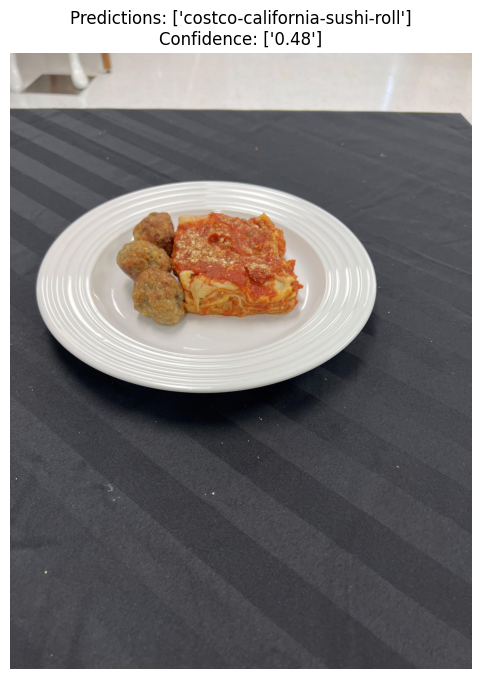

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import cv2
import pandas as pd
import random
from sklearn.preprocessing import LabelEncoder

# Function to predict food category from an image
def predict_food_category(image_path, model, label_encoder):
    # Load and preprocess the image
    image = cv2.imread(image_path)
    if image is None:
        return "Error: Could not load image"
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    # Find food regions using COCO annotations or detect with simple method
    # For demonstration, we'll use a simplified approach
    regions = extract_regions(image)
    
    if not regions:
        # If no regions found, use whole image
        regions = [cv2.resize(image, (IMG_SIZE, IMG_SIZE)) / 255.0]
    
    # Make predictions for each region
    predictions = []
    for region in regions:
        # Ensure region is in the right format for prediction
        region_processed = np.expand_dims(region, axis=0)
        
        # Predict
        pred = model.predict(region_processed, verbose=0)
        class_idx = np.argmax(pred, axis=1)[0]
        confidence = np.max(pred)
        
        # Get the category name
        try:
            category_id = label_encoder.classes_[class_idx]
            category_name = next((cat['name'] for cat in category if cat['id'] == category_id), "Unknown")
            predictions.append((category_name, confidence))
        except:
            predictions.append(("Unknown", confidence))
    
    return predictions

# Function to extract regions from an image (simplified)
def extract_regions(image):
    regions = []
    
    # For now, just return the whole image resized
    resized_img = cv2.resize(image, (IMG_SIZE, IMG_SIZE)) / 255.0
    regions.append(resized_img)
    
    return regions

# Define constants
IMG_SIZE = 224  # Input size for MobileNetV2
BATCH_SIZE = 64
EPOCHS = 15

# Load the saved model
model_path = "224_15_Epoch_raw_new.keras"
food_detection_model = tf.keras.models.load_model(model_path)

# Setting paths
base_path = 'nutritionverse-data'
images_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images')
coco_json_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/images/_annotations.coco.json')
splits_path = os.path.join(base_path, 'nutritionverse-manual/nutritionverse-manual/updated-manual-dataset-splits.csv')

# Load COCO format image metadata
with open(coco_json_path, 'r') as f:
    coco_data = json.load(f)

# Optionally extract image information from COCO format
coco_images = pd.DataFrame(coco_data['images'])

# Create a mapping from image_id to file_name
image_id_to_filename = {img['id']: img['file_name'] for img in coco_data['images']}
print(f"Created mapping for {len(image_id_to_filename)} image IDs to filenames")


category = coco_data['categories']
# Extract only the 'id' values from the categories
category_ids = [cat['id'] for cat in category]

# Initialize and fit the LabelEncoder
label_encoder = LabelEncoder()
label_encoder.fit(category_ids)


# Test the detection on a sample image
sample_image_id = random.choice(list(image_id_to_filename.keys()))
sample_filename = image_id_to_filename[sample_image_id]
sample_image_path = os.path.join(images_path, sample_filename)

print(f"Testing food detection on image: {sample_filename}")

# Predict food categories
predictions = predict_food_category(sample_image_path, food_detection_model, label_encoder)
print(f"Predicted categories: {predictions}")

# Display the image with predictions
plt.figure(figsize=(10, 8))
img = plt.imread(sample_image_path)
plt.imshow(img)
plt.title(f"Predictions: {[p[0] for p in predictions]}\nConfidence: {[f'{p[1]:.2f}' for p in predictions]}")
plt.axis('off')
plt.show()

